<a href="https://colab.research.google.com/github/oninonins/Machine-learning-/blob/main/JS06%20-%20ANN/Praktikum_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 4 — Perbandingan Annoy vs FAISS vs HNSW

Tiga index dibandingkan pada data yang sama. Masing-masing diukur **waktu build index** (biaya sekali jalan saat preparasi) dan **waktu query** (biaya per permintaan pengguna), lalu hasilnya dicatat pada tabel seperti di Praktikum 1.

| Library | Tipe index | Metrik yang didukung |
|---|---|---|
| **Annoy** | forest random projection | `euclidean`, `angular`, `manhattan` |
| **FAISS** | `IndexFlat` (brute force, **tepat/exact**) | `L2`, `Inner Product`, `L1` |
| **HNSW** | graph berlapis | `l2`, `ip`, `cosine` |

Catatan penting: **FAISS `IndexFlat` bukan ANN**, melainkan pencarian tepat (exact). Ia dipakai sebagai pembanding ENN, sedangkan Annoy dan HNSW yang benar-benar pendekatan. Karena itu pada baris FAISS, indeks ENN dan ANN identik dan recall-nya 1.0.

Jumlah data pada percobaan ini adalah **10.000** (bukan 1.000.000 seperti nilai yang disarankan modul) agar notebook dapat dijalankan cepat di Colab. Nilai dapat diubah melalui `N_DATA` bila ingin mencoba skala yang lebih besar.

In [7]:
!pip install annoy hnswlib faiss-cpu

In [8]:
import numpy as np
import time
import matplotlib.pyplot as plt
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset
# ===============================
N_DATA = 10_000      # jumlah data yang dipakai pada percobaan ini
DIM    = 5
np.random.seed(42)
X = np.random.random((N_DATA, DIM)).astype(np.float32)

# Query point
query = np.random.random((1, DIM)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(DIM, 'euclidean')

start = time.time()
for i in range(N_DATA):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(
    query[0], k, search_k=1000, include_distances=True
)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (IndexFlatL2)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(DIM)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=DIM)

start = time.time()
hnsw_index.init_index(max_elements=N_DATA, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")

=== Annoy ===
Build time: 0.41619157791137695 detik
Query time: 0.0015287399291992188 detik
Neighbors: [9616, 805, 8941, 2186, 1524] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.0014183521270751953 detik
Query time: 0.011811494827270508 detik
Neighbors: [9616  805 8941 2186 1524] ...

=== HNSW (hnswlib) ===
Build time: 1.873171091079712 detik
Query time: 0.0002627372741699219 detik
Neighbors: [9616  805 8941 2186 1524] ...


In [9]:
# -------------------------------
# Percobaan metrik distance berbeda
# -------------------------------
import gc
import pandas as pd

ANN_TREES      = 10
ANN_SEARCH_K   = 1000
HNSW_M         = 16
HNSW_EFC       = 200
HNSW_EF        = 50
K_SWEEP        = 10

# metrik yang didukung tiap library
METRICS = {
    "Euclidean": {
        "enn": "l2",
        "Annoy": "euclidean",
        "FAISS Flat": (faiss.METRIC_L2, False),
        "HNSW": "l2",
    },
    "Angular": {
        "enn": "cosine",
        "Annoy": "angular",
        "FAISS Flat": (faiss.METRIC_INNER_PRODUCT, True),   # True = normalisasi L2 dulu
        "HNSW": "cosine",
    },
    "Manhattan (L1)": {
        "enn": "l1",
        "Annoy": "manhattan",
        "FAISS Flat": (faiss.METRIC_L1, False),
        "HNSW": None,                                      # hnswlib tidak punya L1
    },
}


def enn_topk(X, q, metric, k=K_SWEEP):
    """Brute force dengan definisi jarak yang sama dengan masing-masing library:
       l2 -> sum((x-q)^2), cosine -> 1 - cos(x,q), l1 -> sum(|x-q|)."""
    if metric == "l2":
        d = np.sum((X - q) ** 2, axis=1)
    elif metric == "cosine":
        d = 1.0 - (X @ q) / (np.maximum(np.linalg.norm(X, axis=1), 1e-12) * np.linalg.norm(q))
    else:
        d = np.sum(np.abs(X - q), axis=1)
    idx = np.argpartition(d, k)[:k]
    return idx[np.argsort(d[idx])]


def normalize(X):
    return (X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)).astype(np.float32)


rows = []

for metric_name, spec in METRICS.items():
    # ---------- baseline ENN (brute force numpy) ----------
    t0 = time.perf_counter()
    enn_idx = list(map(int, enn_topk(X, query[0], spec["enn"], K_SWEEP)))
    t_enn = (time.perf_counter() - t0) * 1000
    rows.append({
        "Algoritma": "ENN (brute force numpy)",
        "Distance Metrics": metric_name,
        "Tree": "-",
        "Jumlah data": N_DATA,
        "ENN top-10": enn_idx,
        "ANN top-10": enn_idx,
        "Recall@10": 1.0,
        "Waktu build (s)": 0.0,
        "Waktu query (ms)": round(t_enn, 4),
    })

    # ---------- Annoy ----------
    idx_ann = AnnoyIndex(DIM, spec["Annoy"])
    t0 = time.perf_counter()
    for i in range(N_DATA):
        idx_ann.add_item(i, X[i])
    idx_ann.build(ANN_TREES)
    t_build = time.perf_counter() - t0
    t0 = time.perf_counter()
    ann_idx = list(map(int, idx_ann.get_nns_by_vector(
        query[0], K_SWEEP, search_k=ANN_SEARCH_K
    )))
    t_query = (time.perf_counter() - t0) * 1000
    rows.append({
        "Algoritma": "Annoy",
        "Distance Metrics": metric_name,
        "Tree": f"{ANN_TREES} trees, search_k={ANN_SEARCH_K}",
        "Jumlah data": N_DATA,
        "ENN top-10": enn_idx,
        "ANN top-10": ann_idx,
        "Recall@10": round(len(set(enn_idx) & set(ann_idx)) / K_SWEEP, 3),
        "Waktu build (s)": round(t_build, 3),
        "Waktu query (ms)": round(t_query, 4),
    })
    del idx_ann
    gc.collect()

    # ---------- FAISS Flat ----------
    f_metric, need_norm = spec["FAISS Flat"]
    Xf = normalize(X) if need_norm else X
    qf = normalize(query) if need_norm else query
    faiss_idx = faiss.index_factory(DIM, "Flat", f_metric)   # kelas L1 tidak ada di FAISS terbaru
    t0 = time.perf_counter()
    faiss_idx.add(Xf)
    t_build = time.perf_counter() - t0
    t0 = time.perf_counter()
    _, faiss_res = faiss_idx.search(qf, K_SWEEP)
    t_query = (time.perf_counter() - t0) * 1000
    ann_idx = list(map(int, faiss_res[0]))
    rows.append({
        "Algoritma": "FAISS Flat (exact)",
        "Distance Metrics": metric_name,
        "Tree": "Flat",
        "Jumlah data": N_DATA,
        "ENN top-10": enn_idx,
        "ANN top-10": ann_idx,
        "Recall@10": round(len(set(enn_idx) & set(ann_idx)) / K_SWEEP, 3),
        "Waktu build (s)": round(t_build, 3),
        "Waktu query (ms)": round(t_query, 4),
    })
    del faiss_idx
    gc.collect()

    # ---------- HNSW ----------
    if spec["HNSW"] is not None:
        hnsw = hnswlib.Index(space=spec["HNSW"], dim=DIM)
        t0 = time.perf_counter()
        hnsw.init_index(max_elements=N_DATA, ef_construction=HNSW_EFC, M=HNSW_M)
        hnsw.add_items(X)
        t_build = time.perf_counter() - t0
        hnsw.set_ef(HNSW_EF)
        t0 = time.perf_counter()
        labels, _ = hnsw.knn_query(query, k=K_SWEEP)
        t_query = (time.perf_counter() - t0) * 1000
        ann_idx = list(map(int, labels[0]))
        rows.append({
            "Algoritma": "HNSW",
            "Distance Metrics": metric_name,
            "Tree": f"M={HNSW_M}, ef={HNSW_EF}",
            "Jumlah data": N_DATA,
            "ENN top-10": enn_idx,
            "ANN top-10": ann_idx,
            "Recall@10": round(len(set(enn_idx) & set(ann_idx)) / K_SWEEP, 3),
            "Waktu build (s)": round(t_build, 3),
            "Waktu query (ms)": round(t_query, 4),
        })
        del hnsw
        gc.collect()
    else:
        print(f"{metric_name}: HNSW tidak mendukung metrik ini (hnswlib hanya l2/ip/cosine)")

hasil = pd.DataFrame(rows)
display(hasil)

Manhattan (L1): HNSW tidak mendukung metrik ini (hnswlib hanya l2/ip/cosine)


,Algoritma,Distance Metrics,Tree,Jumlah data,ENN top-10,ANN top-10,Recall@10,Waktu build (s),Waktu query (ms)
0,ENN (brute force numpy),Euclidean,-,10000,"[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...","[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...",1.0,0.000,0.7349
1,Annoy,Euclidean,"10 trees, search_k=1000",10000,"[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...","[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...",1.0,0.328,0.2496
2,FAISS Flat (exact),Euclidean,Flat,10000,"[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...","[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...",1.0,0.000,15.3151
3,HNSW,Euclidean,"M=16, ef=50",10000,"[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...","[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...",1.0,1.909,0.0959
4,ENN (brute force numpy),Angular,-,10000,"[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...","[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...",1.0,0.000,0.7883
5,Annoy,Angular,"10 trees, search_k=1000",10000,"[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...","[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...",1.0,0.569,0.2576
6,FAISS Flat (exact),Angular,Flat,10000,"[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...","[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...",1.0,0.000,20.8122
7,HNSW,Angular,"M=16, ef=50",10000,"[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...","[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...",1.0,1.736,0.0920
8,ENN (brute force numpy),Manhattan (L1),-,10000,"[9616, 2186, 805, 1524, 8941, 8077, 9737, 4150...","[9616, 2186, 805, 1524, 8941, 8077, 9737, 4150...",1.0,0.000,0.7371
9,Annoy,Manhattan (L1),"10 trees, search_k=1000",10000,"[9616, 2186, 805, 1524, 8941, 8077, 9737, 4150...","[9616, 2186, 805, 1524, 8941, 8077, 9737, 4150...",1.0,0.409,0.2608


In [10]:
# Tabel laporan (format Praktikum 1)
def label_baris(metric, algo):
    if algo.startswith("ENN"):
        return f"{metric} — ENN"
    return f"{metric} — {algo}"


tabel = pd.DataFrame({
    "Distance Metrics": [label_baris(m, a) for m, a in zip(hasil["Distance Metrics"], hasil["Algoritma"])],
    "Tree": hasil["Tree"],
    "Jumlah data": hasil["Jumlah data"],
    "Hasil Index terdekat ENN vs ANN": [
        f"ENN: {e} vs ANN: {a} (recall@10={r})"
        for e, a, r in zip(hasil["ENN top-10"], hasil["ANN top-10"], hasil["Recall@10"])],
    "Waktu komputasi": [
        f"build {b} s; query {q} ms"
        for b, q in zip(hasil["Waktu build (s)"], hasil["Waktu query (ms)"])],
})

display(hasil)                       # detail semua kolom
try:
    display(tabel.style.hide(axis='index'))   # butuh paket jinja2
except Exception:
    display(tabel)
try:
    print(tabel.to_markdown(index=False))     # butuh paket tabulate
except ImportError:
    print(tabel.to_string(index=False))       # fallback kalau tabulate belum ada

,Algoritma,Distance Metrics,Tree,Jumlah data,ENN top-10,ANN top-10,Recall@10,Waktu build (s),Waktu query (ms)
0,ENN (brute force numpy),Euclidean,-,10000,"[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...","[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...",1.0,0.000,0.7349
1,Annoy,Euclidean,"10 trees, search_k=1000",10000,"[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...","[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...",1.0,0.328,0.2496
2,FAISS Flat (exact),Euclidean,Flat,10000,"[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...","[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...",1.0,0.000,15.3151
3,HNSW,Euclidean,"M=16, ef=50",10000,"[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...","[9616, 805, 8941, 2186, 1524, 4150, 6272, 7725...",1.0,1.909,0.0959
4,ENN (brute force numpy),Angular,-,10000,"[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...","[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...",1.0,0.000,0.7883
5,Annoy,Angular,"10 trees, search_k=1000",10000,"[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...","[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...",1.0,0.569,0.2576
6,FAISS Flat (exact),Angular,Flat,10000,"[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...","[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...",1.0,0.000,20.8122
7,HNSW,Angular,"M=16, ef=50",10000,"[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...","[1594, 9616, 1056, 805, 4150, 3766, 8941, 4886...",1.0,1.736,0.0920
8,ENN (brute force numpy),Manhattan (L1),-,10000,"[9616, 2186, 805, 1524, 8941, 8077, 9737, 4150...","[9616, 2186, 805, 1524, 8941, 8077, 9737, 4150...",1.0,0.000,0.7371
9,Annoy,Manhattan (L1),"10 trees, search_k=1000",10000,"[9616, 2186, 805, 1524, 8941, 8077, 9737, 4150...","[9616, 2186, 805, 1524, 8941, 8077, 9737, 4150...",1.0,0.409,0.2608


Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi
Euclidean — ENN,-,10000,"ENN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] vs ANN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] (recall@10=1.0)",build 0.0 s; query 0.7349 ms
Euclidean — Annoy,"10 trees, search_k=1000",10000,"ENN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] vs ANN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] (recall@10=1.0)",build 0.328 s; query 0.2496 ms
Euclidean — FAISS Flat (exact),Flat,10000,"ENN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] vs ANN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] (recall@10=1.0)",build 0.0 s; query 15.3151 ms
Euclidean — HNSW,"M=16, ef=50",10000,"ENN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] vs ANN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] (recall@10=1.0)",build 1.909 s; query 0.0959 ms
Angular — ENN,-,10000,"ENN: [1594, 9616, 1056, 805, 4150, 3766, 8941, 4886, 7462, 1524] vs ANN: [1594, 9616, 1056, 805, 4150, 3766, 8941, 4886, 7462, 1524] (recall@10=1.0)",build 0.0 s; query 0.7883 ms
Angular — Annoy,"10 trees, search_k=1000",10000,"ENN: [1594, 9616, 1056, 805, 4150, 3766, 8941, 4886, 7462, 1524] vs ANN: [1594, 9616, 1056, 805, 4150, 3766, 8941, 4886, 7462, 1524] (recall@10=1.0)",build 0.569 s; query 0.2576 ms
Angular — FAISS Flat (exact),Flat,10000,"ENN: [1594, 9616, 1056, 805, 4150, 3766, 8941, 4886, 7462, 1524] vs ANN: [1594, 9616, 1056, 805, 4150, 3766, 8941, 4886, 7462, 1524] (recall@10=1.0)",build 0.0 s; query 20.8122 ms
Angular — HNSW,"M=16, ef=50",10000,"ENN: [1594, 9616, 1056, 805, 4150, 3766, 8941, 4886, 7462, 1524] vs ANN: [1594, 9616, 1056, 805, 4150, 3766, 8941, 4886, 7462, 1524] (recall@10=1.0)",build 1.736 s; query 0.092 ms
Manhattan (L1) — ENN,-,10000,"ENN: [9616, 2186, 805, 1524, 8941, 8077, 9737, 4150, 2537, 3393] vs ANN: [9616, 2186, 805, 1524, 8941, 8077, 9737, 4150, 2537, 3393] (recall@10=1.0)",build 0.0 s; query 0.7371 ms
Manhattan (L1) — Annoy,"10 trees, search_k=1000",10000,"ENN: [9616, 2186, 805, 1524, 8941, 8077, 9737, 4150, 2537, 3393] vs ANN: [9616, 2186, 805, 1524, 8941, 8077, 9737, 4150, 2537, 3393] (recall@10=1.0)",build 0.409 s; query 0.2608 ms


| Distance Metrics                    | Tree                    |   Jumlah data | Hasil Index terdekat ENN vs ANN                                                                                                                      | Waktu komputasi                |
|:------------------------------------|:------------------------|--------------:|:-----------------------------------------------------------------------------------------------------------------------------------------------------|:-------------------------------|
| Euclidean — ENN                     | -                       |         10000 | ENN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] vs ANN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] (recall@10=1.0) | build 0.0 s; query 0.7349 ms   |
| Euclidean — Annoy                   | 10 trees, search_k=1000 |         10000 | ENN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725, 2537, 6516] vs ANN: [9616, 805, 8941, 2186, 1524, 4150, 6272, 7725,

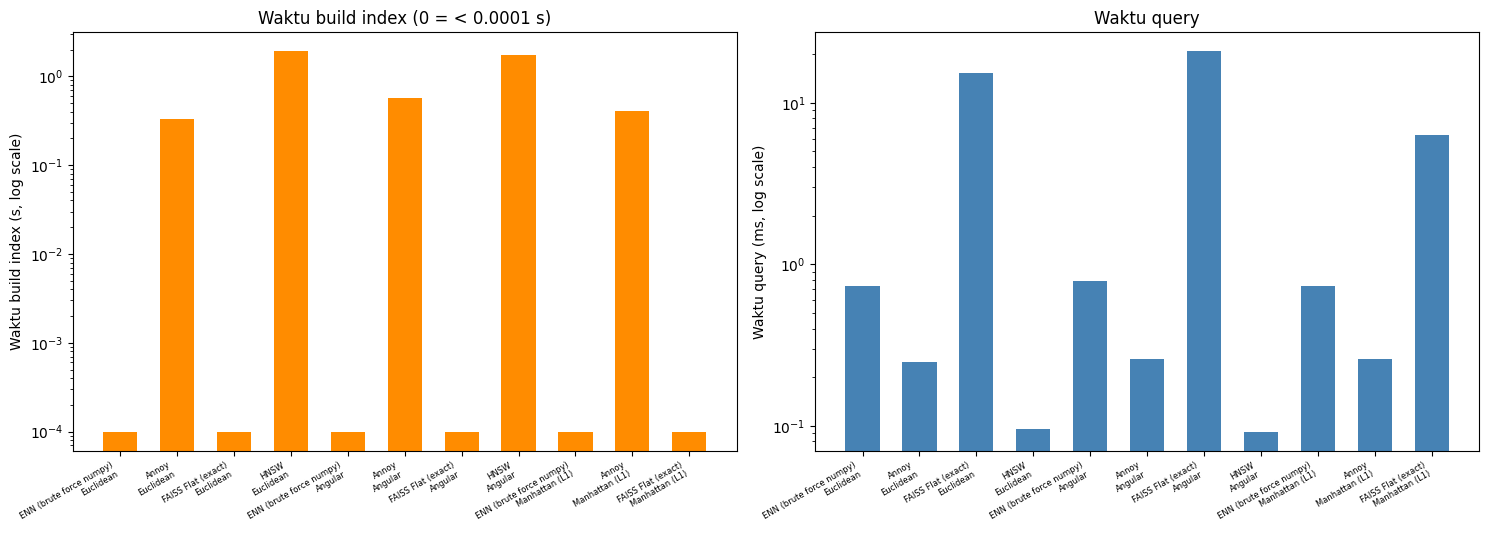

In [11]:
labels = [f"{r['Algoritma']}\n{r['Distance Metrics']}" for _, r in hasil.iterrows()]
x = np.arange(len(hasil))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

# ENN dan FAISS Flat punya build time ~0, sehingga diganti batas bawah kecil
# agar tetap tampil pada sumbu log (0 = kurang dari 0.0001 s).
build_plot = hasil["Waktu build (s)"].clip(lower=1e-4)

ax[0].bar(x, build_plot, 0.6, color="darkorange")
ax[0].set_yscale("log")
ax[0].set_xticks(x); ax[0].set_xticklabels(labels, fontsize=6)
ax[0].set_ylabel("Waktu build index (s, log scale)")
ax[0].set_title("Waktu build index (0 = < 0.0001 s)")
plt.setp(ax[0].get_xticklabels(), rotation=30, ha="right")

ax[1].bar(x, hasil["Waktu query (ms)"], 0.6, color="steelblue")
ax[1].set_yscale("log")
ax[1].set_xticks(x); ax[1].set_xticklabels(labels, fontsize=6)
ax[1].set_ylabel("Waktu query (ms, log scale)")
ax[1].set_title("Waktu query")
plt.setp(ax[1].get_xticklabels(), rotation=30, ha="right")

plt.tight_layout(); plt.show()

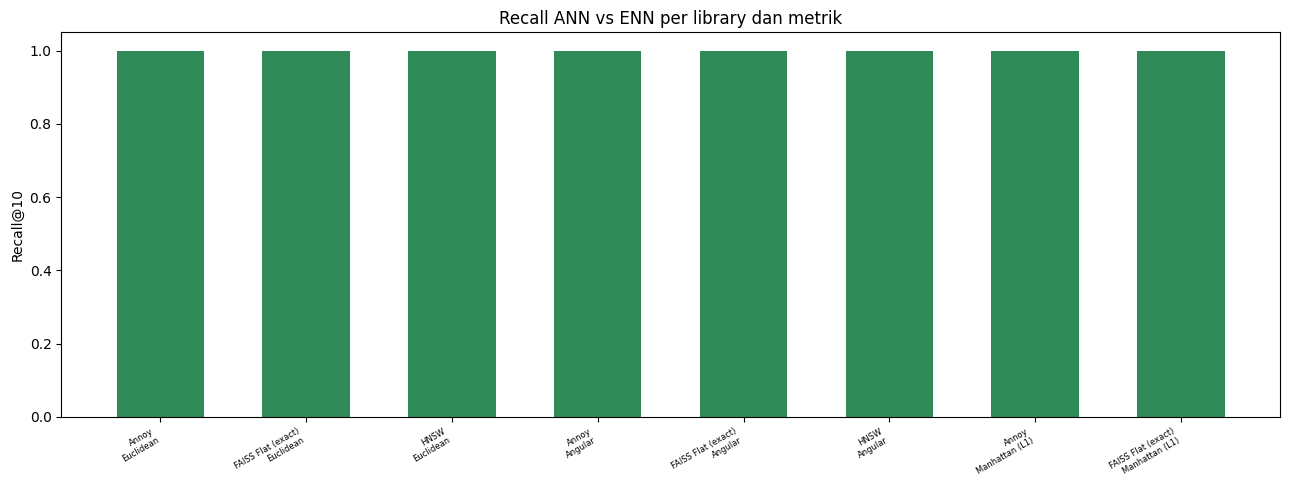

In [12]:
# Recall@10 per library (1.0 = identik dengan exact)
fig, ax = plt.subplots(figsize=(13, 5))
sub = hasil[hasil["Algoritma"] != "ENN (brute force numpy)"]
x2 = np.arange(len(sub))
ax.bar(x2, sub["Recall@10"], 0.6, color="seagreen")
ax.set_ylim(0, 1.05)
ax.set_xticks(x2)
ax.set_xticklabels([f"{r['Algoritma']}\n{r['Distance Metrics']}" for _, r in sub.iterrows()], fontsize=6)
ax.set_ylabel("Recall@10")
ax.set_title("Recall ANN vs ENN per library dan metrik")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.show()

## Cara membaca hasil

- **Recall@10** = porsi dari 10 tetangga ENN yang juga dikembalikan index ANN. Nilai 1.0 berarti jawabannya identik dengan brute force.
- **FAISS `IndexFlat` adalah exact, bukan ANN.** Ia tidak punya proses build yang berat, tetapi query-nya selalu memindai seluruh data. Di tabel ia ditandai "FAISS Flat (exact)" dan recall-nya 1.0.
- **Annoy** membangun forest dari random projection. `n_trees` adalah parameter build (makin banyak tree, recall makin tinggi, memori dan waktu build makin besar), sedangkan `search_k` adalah parameter query (kontrol berapa banyak node yang diperiksa). Pada percobaan ini `n_trees=10` dan `search_k=1000`.
- **HNSW** membangun graph. `M` = tetangga per node, `ef_construction` = ketelitian saat build, `ef` = ketelitian saat query. **`ef` adalah tombol trade-off utama** HNSW.
- **Metrik tidak seragam antar library**: `manhattan` hanya ada di Annoy dan FAISS, sedangkan hnswlib hanya menyediakan `l2`, `ip`, dan `cosine`. Karena itu baris Manhattan untuk HNSW memang tidak dibuat, bukan karena gagal.
- **Angular** di FAISS memakai `METRIC_INNER_PRODUCT` atas vektor yang sudah dinormalisasi L2, sehingga ekuivalen dengan cosine. Tanpa normalisasi, inner product akan terpengaruh oleh panjang vektor.
- **Waktu komputasi** dipecah dua: **build** (sekali jalan saat preparasi) dan **query** (per permintaan). Untuk sistem rekomendasi dengan banyak query, yang kedua lebih menentukan. Nilai build 0 pada grafik berarti di bawah 0.0001 detik, bukan benar-benar nol.
- Pada data acak dimensi tinggi, jarak antar kandidat bisa hampir sama sehingga recall dapat turun walau algoritmanya benar. Pada percobaan 5D ini recall semua metode tetap 1.0, tetapi efek tersebut bisa muncul pada dimensi yang lebih tinggi.

## Catatan hasil

Pada dataset 10.000 x 5D, seluruh metode memperoleh **recall@10 = 1.0**, termasuk Annoy dengan `n_trees=10` dan `search_k=1000`. Artinya pada skala ini ketiga library mengembalikan tetangga yang sama dengan exact NN.

Waktu build: **FAISS Flat ~0 s** (hanya menyimpan vektor), **Annoy 0.33-0.57 s**, dan **HNSW 1.74-1.91 s**. Waktu query: **HNSW 0.092-0.096 ms**, **Annoy 0.25-0.26 ms**, dan **FAISS Flat 6.29-20.81 ms**. FAISS Flat paling lambat saat query karena harus memindai seluruh data, sedangkan HNSW dan Annoy memanfaatkan struktur index. Angka pasti dapat berbeda antar mesin; jalankan notebook untuk melihat nilai aktual.